# A/B-тест новой формы оплаты ЖКХ

Кейс на позицию продуктового аналитика. Команда платежей протестировала новую форму оплаты ЖКХ с автозаполнением реквизитов.

* **Воронка:** 1. Открыл форму → 2. Ввёл реквизиты → 3. Подтвердил платёж → 4. Успешная оплата
* **Ключевая метрика:** конверсия из шага 1 в шаг 4 (по попыткам оплаты)
* **Период:** 1–30 апреля 2024, сплит по клиентам
* **Вопрос:** запускать новую форму на всех пользователей или нет

**Итог:** конверсия 1→4 выросла с 49,8% до 64,4% (+14,6 п.п., 95% ДИ [10,9; 18,3], p < 0,001). Эффект есть во всех сегментах и все недели теста, контрольные метрики не ухудшились → **рекомендация: раскатывать**. Отчёт: [`report/AB_test_ZhKH_Kurilenko.pdf`](report/AB_test_ZhKH_Kurilenko.pdf).

Содержание: 1) загрузка → 2) качество данных → 3) очистка → 4) корректность сплита → 5) ключевая метрика → 6) дополнительные метрики → 7) сегменты и динамика → 8) графики → 9) вывод.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

ALPHA = 0.05
SEED = 42
STEPS = ["step1_opened", "step2_entered", "step3_confirmed", "step4_success"]

## 1. Загрузка данных

Excel-файл кейса не входит в репозиторий: положите его в папку `data/` (подойдёт любое имя `*.xlsx`).

In [2]:
files = sorted(DATA_DIR.glob("*.xlsx"))
assert files, "Положите Excel-файл кейса в папку data/"
sheets = pd.read_excel(files[0], sheet_name=None)
users_raw = sheets["Пользователи"]
payments_raw = sheets["Платежи"]

print(f"Пользователи: {users_raw.shape}, Платежи: {payments_raw.shape}")
display(users_raw.head())
display(payments_raw.head())

Пользователи: (1504, 5), Платежи: (2661, 7)


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


## 2. Проверка качества данных

### 2.1 Пользователи

In [3]:
u = users_raw
print("Пропуски по столбцам:\n", u.isna().sum(), sep="")
print("\nДубликаты user_id:", u.user_id.duplicated().sum())
print("Диапазон user_id:", u.user_id.min(), "–", u.user_id.max())
display(u.describe(include="all"))

Пропуски по столбцам:
user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

Дубликаты user_id: 0
Диапазон user_id: 1001 – 9004


,user_id,group,age,city,device_type
count,1504.000000,1503,1504.000000,1503,1504
unique,NaN,2,NaN,3,2
top,NaN,A,NaN,Москва,android
freq,NaN,752,NaN,595,777
mean,1769.787234,NaN,32.745346,NaN,NaN
std,571.592080,NaN,8.410915,NaN,NaN
min,1001.000000,NaN,-5.000000,NaN,NaN
25%,1376.750000,NaN,27.000000,NaN,NaN
50%,1752.500000,NaN,33.000000,NaN,NaN
75%,2128.250000,NaN,38.000000,NaN,NaN


Видны пропуски в `group` и `city`, невозможный возраст (min −5, max 150) и user_id вне основного диапазона 1001–2500:

In [4]:
suspicious_users = u[u.isna().any(axis=1) | ~u.age.between(14, 100) | (u.user_id > 2500)]
suspicious_users

,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios
1503,9004,A,30,NaN,android


### 2.2 Платежи

In [5]:
p = payments_raw
print("Пропуски по столбцам:\n", p.isna().sum(), sep="")
print("\nДубликаты payment_id:", p.payment_id.duplicated().sum())
print("Полные дубликаты (без payment_id):", p.duplicated(subset=p.columns.drop("payment_id")).sum())

# пропуски шагов: шаг k+1 есть, а шага k нет
filled = p[STEPS].notna()
skipped = (filled[STEPS[1:]].values & ~filled[STEPS[:-1]].values).any(axis=1)
print("Попыток с пропущенным промежуточным шагом:", skipped.sum())

# нарушение порядка времени между шагами
wrong_order = np.zeros(len(p), dtype=bool)
for a, b in zip(STEPS[:-1], STEPS[1:]):
    wrong_order |= (p[b] < p[a]).values
print("Попыток с нарушенным порядком времени:", wrong_order.sum())

out_of_window = ~p.step1_opened.between("2024-04-01", "2024-04-30 23:59:59")
print("Попыток вне периода теста:", out_of_window.sum())

Пропуски по столбцам:
payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

Дубликаты payment_id: 0
Полные дубликаты (без payment_id): 0
Попыток с пропущенным промежуточным шагом: 0
Попыток с нарушенным порядком времени: 0
Попыток вне периода теста: 0


In [6]:
# длительность переходов между шагами (минуты) — ищем выбросы
durations = pd.DataFrame({
    f"{a[:5]}→{b[:5]}": (p[b] - p[a]).dt.total_seconds() / 60
    for a, b in zip(STEPS[:-1], STEPS[1:])
})
display(durations.describe().round(1))
print("Попыток на пользователя:")
print(p.groupby("user_id").size().value_counts().sort_index())

,step1→step2,step2→step3,step3→step4
count,2256.0,1719.0,1522.0
mean,2.4,4.5,5.5
std,1.9,1.9,1.1
min,1.0,1.0,1.0
25%,1.0,3.0,5.0
50%,1.0,4.0,6.0
75%,3.0,6.0,6.0
max,13.0,11.0,9.0


Попыток на пользователя:
1    740
2    443
3    238
4     80
Name: count, dtype: int64


Длительности правдоподобные (1–13 мин между шагами), выбросов нет. Проверяем связь платежей с пользователями и согласованность групп:

In [7]:
check = p.merge(u[["user_id", "group"]], on="user_id", how="left", suffixes=("", "_user"))
print("Платежей без user_id:", p.user_id.isna().sum())
print("Платежей пользователей, которых нет в листе «Пользователи»:", (check.user_id.notna() & check.group_user.isna()).sum())
mismatch = check[check.group_user.notna() & (check.group != check.group_user)]
print("Платежей, у которых группа не совпадает с группой пользователя:", len(mismatch))
display(mismatch)
ids = p.payment_id.sort_values()
first_after_gap = ids[ids.diff() > 1].min()  # первый ID после разрыва сквозной нумерации
print(f"payment_id идут подряд от {ids.min()} до {ids[ids < first_after_gap].max()}, дальше — отдельные записи:")
display(p[p.payment_id >= first_after_gap])

Платежей без user_id: 1
Платежей пользователей, которых нет в листе «Пользователи»: 0
Платежей, у которых группа не совпадает с группой пользователя: 1


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,group_user
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A


payment_id идут подряд от 5001 до 7658, дальше — отдельные записи:


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


**Найденные проблемы:**

| Запись | Проблема | Решение |
|---|---|---|
| user 9001 | нет группы | исключить: нельзя отнести к ветке |
| user 9002, 9003 | возраст −5 и 150 | обнулить возраст; платежей у них нет, на метрику не влияют |
| user 9004 | нет города | оставить, город = «Не указан»: группа и платёж корректны |
| payment 99003 | нет user_id | исключить |
| payment 99002 | клиент 1010 из A провёл платёж в форме B | исключить клиента целиком: видел обе версии, нарушение сплита |
| payment 99001 | ID вне сквозной нумерации 5001–7658 | исключить как техническую запись |

## 3. Очистка

In [8]:
def clean(users: pd.DataFrame, payments: pd.DataFrame):
    users, payments = users.copy(), payments.copy()
    log = []

    no_group = users.group.isna()
    log.append(("Пользователь без группы", no_group.sum()))
    users = users[~no_group]

    bad_age = ~users.age.between(14, 100)
    log.append(("Невалидный возраст → NaN", bad_age.sum()))
    users.loc[bad_age, "age"] = np.nan
    users["city"] = users.city.fillna("Не указан")

    no_uid = payments.user_id.isna()
    log.append(("Платёж без user_id", no_uid.sum()))
    payments = payments[~no_uid].astype({"user_id": int})

    merged = payments.merge(users[["user_id", "group"]], on="user_id", how="left", suffixes=("", "_user"))
    contaminated = set(merged.loc[merged.group_user.notna() & (merged.group != merged.group_user), "user_id"])
    log.append(("Пользователь видел обе версии формы (исключён целиком)", len(contaminated)))
    users = users[~users.user_id.isin(contaminated)]
    payments = payments[~payments.user_id.isin(contaminated)]

    odd_id = payments.payment_id > 9000
    log.append(("Платёж с ID вне нумерации", odd_id.sum()))
    payments = payments[~odd_id]

    orphan = ~payments.user_id.isin(users.user_id)
    log.append(("Платёж пользователя не из выборки", orphan.sum()))
    payments = payments[~orphan]

    payments = payments.merge(users[["user_id", "city", "device_type", "age"]], on="user_id")
    for i, col in enumerate(STEPS, start=1):
        payments[f"s{i}"] = payments[col].notna().astype(int)

    return users.reset_index(drop=True), payments.reset_index(drop=True), pd.DataFrame(log, columns=["Проблема", "Записей"])


users, pay, clean_log = clean(users_raw, payments_raw)
display(clean_log)
print(f"После очистки: {len(users)} пользователей, {len(pay)} попыток оплаты")
print("Клиентов в воронке по группам:", pay.groupby("group").user_id.nunique().to_dict())

,Проблема,Записей
0,Пользователь без группы,1
1,Невалидный возраст → NaN,2
2,Платёж без user_id,1
3,Пользователь видел обе версии формы (исключён ...,1
4,Платёж с ID вне нумерации,1
5,Платёж пользователя не из выборки,0


После очистки: 1502 пользователей, 2657 попыток оплаты
Клиентов в воронке по группам: {'A': 750, 'B': 750}


## 4. Корректность сплита

Проверяем, что группы одного размера (SRM) и сопоставимы по составу.

In [9]:
print("Размеры групп:", users.group.value_counts().to_dict())
print(f"SRM (хи-квадрат против 50/50): p = {stats.chisquare(users.group.value_counts().values).pvalue:.3f}")

known_city = users[users.city != "Не указан"]
balance = {
    "device_type (χ²)": stats.chi2_contingency(pd.crosstab(users.group, users.device_type))[1],
    "city (χ²)": stats.chi2_contingency(pd.crosstab(known_city.group, known_city.city))[1],
    "age (Mann–Whitney)": stats.mannwhitneyu(users.loc[users.group == "A", "age"].dropna(),
                                             users.loc[users.group == "B", "age"].dropna()).pvalue,
}
display(pd.Series(balance, name="p-value").round(3))
display(pd.crosstab(users.group, users.device_type, normalize="index").round(3))

Размеры групп: {'A': 751, 'B': 751}
SRM (хи-квадрат против 50/50): p = 1.000


device_type (χ²)      0.056
city (χ²)             0.452
age (Mann–Whitney)    0.840
Name: p-value, dtype: float64

device_type,android,ios
group,,
A,0.542,0.458
B,0.491,0.509


SRM нет, по городу и возрасту группы сбалансированы. По устройству небольшой перекос (Android 54% в A против 49% в B, p ≈ 0,06), поэтому в п. 6 эффект дополнительно проверяется с поправкой на устройство и город.

## 5. Ключевая метрика: конверсия 1 → 4

**Выбор метода.** Рандомизация — по клиентам, а метрика считается по попыткам: у клиента 1–4 попытки. Попытки одного клиента зависимы, поэтому обычный z-тест для долей по попыткам занижает дисперсию. Метрика — ratio: $CR = \sum \text{успехов} / \sum \text{попыток}$ по клиентам группы. Её дисперсию считаем **дельта-методом** на уровне клиента и перепроверяем **бутстрепом по клиентам**.

$H_0$: $CR_A = CR_B$, $H_1$: $CR_A \neq CR_B$, двусторонний тест, $\alpha = 0{,}05$.

In [10]:
def per_user(df):
    return (df.groupby(["user_id", "group"])
              .agg(attempts=("s1", "sum"), success=("s4", "sum"))
              .reset_index())


def ratio_with_delta_var(x):
    # ratio-метрика sum(success)/sum(attempts) и её дисперсия дельта-методом
    n = len(x)
    mx, my = x.attempts.mean(), x.success.mean()
    vx, vy = x.attempts.var(), x.success.var()
    cov = np.cov(x.success, x.attempts)[0, 1]
    var = (vy / mx**2 - 2 * my * cov / mx**3 + my**2 * vx / mx**4) / n
    return x.success.sum() / x.attempts.sum(), var


def ab_ratio_test(df):
    pu = per_user(df)
    pu_a, pu_b = pu[pu.group == "A"], pu[pu.group == "B"]
    cr_a, var_a = ratio_with_delta_var(pu_a)
    cr_b, var_b = ratio_with_delta_var(pu_b)
    diff, se = cr_b - cr_a, np.sqrt(var_a + var_b)
    z = stats.norm.ppf(1 - ALPHA / 2)
    return pd.Series({
        "CR_A": cr_a, "CR_B": cr_b, "diff_pp": diff * 100,
        "ci_low_pp": (diff - z * se) * 100, "ci_high_pp": (diff + z * se) * 100,
        "uplift_rel_%": (cr_b / cr_a - 1) * 100,
        "p_value": 2 * stats.norm.sf(abs(diff / se)),
        "attempts_A": pu_a.attempts.sum(),
        "attempts_B": pu_b.attempts.sum(),
    })


main = ab_ratio_test(pay)
main.round(4)

CR_A               0.4977
CR_B               0.6440
diff_pp           14.6265
ci_low_pp         10.9176
ci_high_pp        18.3353
uplift_rel_%      29.3879
p_value            0.0000
attempts_A      1306.0000
attempts_B      1351.0000
dtype: float64

In [11]:
# проверка: бутстреп по клиентам
pu = per_user(pay)
a = pu.loc[pu.group == "A", ["attempts", "success"]].to_numpy()
b = pu.loc[pu.group == "B", ["attempts", "success"]].to_numpy()
rng = np.random.default_rng(SEED)

boot = np.empty(10_000)
for i in range(len(boot)):
    sa = a[rng.integers(0, len(a), len(a))]
    sb = b[rng.integers(0, len(b), len(b))]
    boot[i] = sb[:, 1].sum() / sb[:, 0].sum() - sa[:, 1].sum() / sa[:, 0].sum()

lo, hi = np.percentile(boot, [2.5, 97.5]) * 100
print(f"Бутстреп 95% ДИ разницы: [{lo:.1f}; {hi:.1f}] п.п.")

# для сравнения — «наивный» z-тест по попыткам (игнорирует зависимость)
z_stat, p_naive = proportions_ztest([b[:, 1].sum(), a[:, 1].sum()], [b[:, 0].sum(), a[:, 0].sum()])
print(f"Наивный z-тест: z = {z_stat:.2f}, p = {p_naive:.1e}")

Бутстреп 95% ДИ разницы: [10.9; 18.3] п.п.
Наивный z-тест: z = 7.62, p = 2.6e-14


Дельта-метод и бутстреп дают одинаковый интервал ≈ [10,9; 18,3] п.п. Эффект значим с большим запасом при любом методе.

## 6. Дополнительные проверки

In [12]:
# 6.1 Метрика на уровне клиента: доля клиентов с ≥1 успешной оплатой
pu["any_success"] = (pu.success > 0).astype(int)
ua, ub = pu[pu.group == "A"], pu[pu.group == "B"]
_, p_user = proportions_ztest([ub.any_success.sum(), ua.any_success.sum()], [len(ub), len(ua)])
print(f"Клиенты с ≥1 успешной оплатой: A = {ua.any_success.mean():.1%}, B = {ub.any_success.mean():.1%}, p = {p_user:.1e}")

# 6.2 Логистическая регрессия с поправкой на устройство и город, кластерные ошибки по клиенту
pay["is_B"] = (pay.group == "B").astype(int)
known = pay[pay.city != "Не указан"]
logit = smf.logit("s4 ~ is_B + C(device_type) + C(city)", data=known).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": known.user_id})
or_ci = np.exp(logit.conf_int().loc["is_B"])
print(f"Логит: OR = {np.exp(logit.params['is_B']):.2f} [{or_ci[0]:.2f}; {or_ci[1]:.2f}], p = {logit.pvalues['is_B']:.1e}")

# 6.3 Мощность: MDE при текущем объёме
p_a, n_a = main.CR_A, main.attempts_A
mde = (stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(0.8)) * np.sqrt(2 * p_a * (1 - p_a) / n_a)
print(f"MDE (α = 0,05, power = 0,8): ≈ {mde * 100:.1f} п.п.")

Клиенты с ≥1 успешной оплатой: A = 65.6%, B = 80.4%, p = 1.1e-10
Логит: OR = 1.82 [1.56; 2.13], p = 3.6e-14
MDE (α = 0,05, power = 0,8): ≈ 5.5 п.п.


In [13]:
# 6.4 Пошаговая воронка
funnel = pay.groupby("group")[["s1", "s2", "s3", "s4"]].sum()
display(funnel)
display((funnel.div(funnel.s1, axis=0) * 100).round(1).rename(columns=lambda c: f"% до {c}"))

rows = []
for prev, nxt in [("s1", "s2"), ("s2", "s3"), ("s3", "s4")]:
    d = pay[pay[prev] == 1].groupby("group")[nxt].agg(["sum", "count"])
    _, pval = proportions_ztest(d.loc[["B", "A"], "sum"], d.loc[["B", "A"], "count"])
    cr = d["sum"] / d["count"]
    rows.append({"переход": f"{prev}→{nxt}", "A, %": cr.A * 100, "B, %": cr.B * 100,
                 "разница, п.п.": (cr.B - cr.A) * 100, "p-value": pval})
pd.DataFrame(rows).round(4)

,s1,s2,s3,s4
group,,,,
A,1306,1060,757,650
B,1351,1194,960,870


,% до s1,% до s2,% до s3,% до s4
group,,,,
A,100.0,81.2,58.0,49.8
B,100.0,88.4,71.1,64.4


,переход,"A, %","B, %","разница, п.п.",p-value
0,s1→s2,81.1639,88.379,7.2151,0.0000
1,s2→s3,71.4151,80.402,8.9869,0.0000
2,s3→s4,85.8653,90.625,4.7597,0.0021


In [14]:
# 6.5 Контрольные (guardrail) метрики
_, p_att = stats.mannwhitneyu(ub.attempts, ua.attempts)
print(f"Попыток на клиента: A = {ua.attempts.mean():.2f}, B = {ub.attempts.mean():.2f}, p = {p_att:.2f}")

paid = pay[pay.s4 == 1].assign(minutes=lambda x: (x.step4_success - x.step1_opened).dt.total_seconds() / 60)
_, p_time = stats.mannwhitneyu(paid.loc[paid.group == "B", "minutes"], paid.loc[paid.group == "A", "minutes"])
print(f"Медиана времени до оплаты: A = {paid.loc[paid.group == 'A', 'minutes'].median():.0f} мин, "
      f"B = {paid.loc[paid.group == 'B', 'minutes'].median():.0f} мин, p = {p_time:.2f}")

Попыток на клиента: A = 1.74, B = 1.80, p = 0.14
Медиана времени до оплаты: A = 12 мин, B = 12 мин, p = 0.41


In [15]:
# 6.6 Чувствительность к очистке: та же метрика на сырых данных
raw = payments_raw.dropna(subset=["user_id"])
(raw.groupby("group").step4_success.count() / raw.groupby("group").size()).round(4)

group
A    0.4977
B    0.6442
dtype: float64

## 7. Сегменты и динамика

In [16]:
segments = {"Все": pay,
            "Android": pay[pay.device_type == "android"], "iOS": pay[pay.device_type == "ios"],
            "Москва": pay[pay.city == "Москва"], "СПб": pay[pay.city == "СПб"], "Регион": pay[pay.city == "Регион"]}
seg = pd.DataFrame({name: ab_ratio_test(df) for name, df in segments.items()}).T
display(seg[["CR_A", "CR_B", "diff_pp", "ci_low_pp", "ci_high_pp", "p_value"]].round(4))

# значимость различий эффекта между сегментами (взаимодействие)
m_dev = smf.logit("s4 ~ is_B * C(device_type)", data=pay).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pay.user_id})
m_city = smf.logit("s4 ~ is_B * C(city)", data=known).fit(disp=0, cov_type="cluster", cov_kwds={"groups": known.user_id})
print("p взаимодействия группа × устройство:", round(m_dev.pvalues["is_B:C(device_type)[T.ios]"], 3))
print("p взаимодействия группа × город:", m_city.pvalues.filter(like="is_B:").round(3).to_dict())

,CR_A,CR_B,diff_pp,ci_low_pp,ci_high_pp,p_value
Все,0.4977,0.6440,14.6265,10.9176,18.3353,0.0000
Android,0.4895,0.6381,14.8657,9.7806,19.9508,0.0000
iOS,0.5076,0.6496,14.2047,8.7707,19.6386,0.0000
Москва,0.4680,0.6508,18.2794,12.4550,24.1037,0.0000
СПб,0.5262,0.6685,14.2377,7.1564,21.3190,0.0001
Регион,0.5076,0.6145,10.6894,4.1224,17.2564,0.0014


p взаимодействия группа × устройство: 0.888
p взаимодействия группа × город: {'is_B:C(city)[T.Регион]': 0.09, 'is_B:C(city)[T.СПб]': 0.437}


In [17]:
pay["week"] = ((pay.step1_opened.dt.day - 1) // 7 + 1).clip(upper=4)  # 4-я неделя = 22–30 апреля
weekly = pay.groupby(["week", "group"]).s4.mean().unstack()
weekly["разница, п.п."] = (weekly.B - weekly.A) * 100
weekly.round(3)

group,A,B,"разница, п.п."
week,,,
1,0.508,0.663,15.466
2,0.523,0.660,13.608
3,0.480,0.623,14.324
4,0.484,0.629,14.500


Эффект положителен и значим во всех сегментах, различия между сегментами незначимы (в регионах прирост ниже, p взаимодействия ≈ 0,09 — стоит мониторить). Разрыв между группами стабилен все 4 недели, признаков эффекта новизны нет.

## 8. Графики

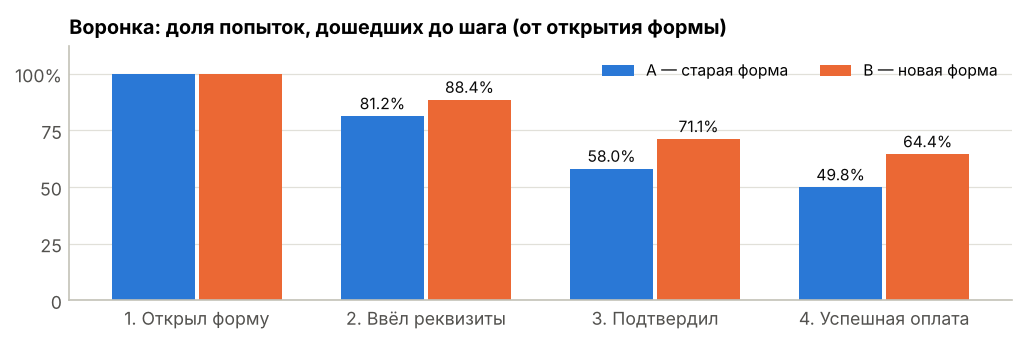

In [18]:
CA, CB = "#2a78d6", "#eb6834"
INK, INK2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({"font.size": 8.5, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 9.5, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})

def style(ax):
    ax.yaxis.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

# воронка
fig, ax = plt.subplots(figsize=(6.9, 2.35), dpi=150)
x, w = np.arange(4), 0.36
for i, (g, c, label) in enumerate([("A", CA, "A — старая форма"), ("B", CB, "B — новая форма")]):
    vals = (funnel.loc[g] / funnel.loc[g, "s1"]).values * 100
    pos = x + (i - 0.5) * (w + 0.02)
    ax.bar(pos, vals, w, color=c, label=label)
    for xi, v in zip(pos[1:], vals[1:]):
        ax.text(xi, v + 1.5, f"{v:.1f}%", ha="center", va="bottom", fontsize=7.5, color=INK)
ax.set_xticks(x, ["1. Открыл форму", "2. Ввёл реквизиты", "3. Подтвердил", "4. Успешная оплата"])
ax.set_ylim(0, 112)
ax.set_yticks([0, 25, 50, 75, 100], ["0", "25", "50", "75", "100%"])
ax.set_title("Воронка: доля попыток, дошедших до шага (от открытия формы)")
ax.legend(frameon=False, loc="upper right", ncol=2, fontsize=7.5)
style(ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "funnel.png", dpi=220, facecolor="white")
plt.show()

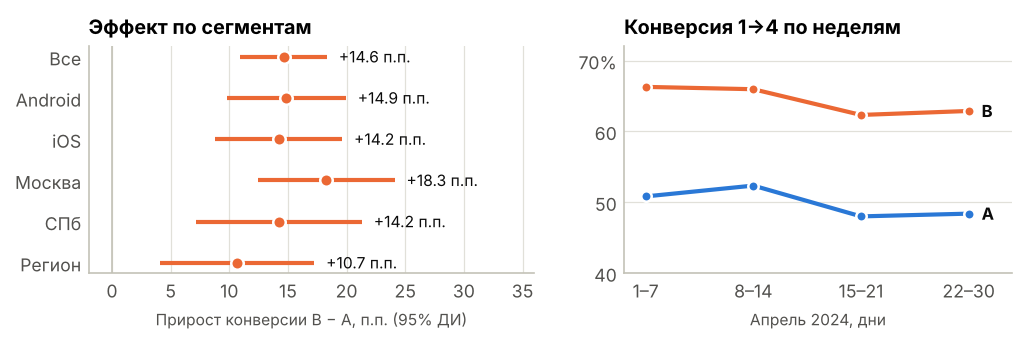

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.9, 2.35), dpi=150, gridspec_kw={"width_ratios": [1.15, 1]})

# эффект по сегментам
s = seg.iloc[::-1]
ys = np.arange(len(s))
ax1.hlines(ys, s.ci_low_pp, s.ci_high_pp, color=CB, lw=2)
ax1.plot(s.diff_pp, ys, "o", ms=6, color=CB, mec="white", mew=1.2)
for y, (_, r) in zip(ys, s.iterrows()):
    ax1.text(r.ci_high_pp + 1, y, f"+{r.diff_pp:.1f} п.п.", va="center", fontsize=7.5, color=INK)
ax1.axvline(0, color=AXIS, lw=0.8)
ax1.set_yticks(ys, s.index)
ax1.set_xlim(-2, 36)
ax1.set_xlabel("Прирост конверсии B − A, п.п. (95% ДИ)", fontsize=7.5)
ax1.xaxis.grid(True, color=GRID, lw=0.6)
ax1.set_axisbelow(True)
ax1.tick_params(length=0)
ax1.set_title("Эффект по сегментам")

# динамика по неделям
for g, c in [("A", CA), ("B", CB)]:
    v = weekly[g].values * 100
    ax2.plot(weekly.index, v, color=c, lw=2, marker="o", ms=5, mec="white", mew=1.2)
    ax2.text(4.12, v[-1], g, va="center", fontsize=8, color=INK, fontweight="bold")
ax2.set_xticks([1, 2, 3, 4], ["1–7", "8–14", "15–21", "22–30"])
ax2.set_ylim(40, 72)
ax2.set_xlim(0.8, 4.4)
ax2.set_yticks([40, 50, 60, 70], ["40", "50", "60", "70%"])
ax2.set_xlabel("Апрель 2024, дни", fontsize=7.5)
ax2.set_title("Конверсия 1→4 по неделям")
style(ax2)

fig.tight_layout(w_pad=2.5)
fig.savefig(FIG_DIR / "segments.png", dpi=220, facecolor="white")
plt.show()

## 9. Вывод и рекомендация

* Новая форма повышает конверсию «открыл форму → успешная оплата» с **49,8% до 64,4%** (+14,6 п.п., +29% относительно; 95% ДИ [10,9; 18,3] п.п.; p < 0,001). Вывод устойчив к выбору метода (дельта-метод, бутстреп, логит с поправкой на состав групп) и к очистке данных.
* Улучшается каждый шаг воронки, сильнее всего — переход «ввёл реквизиты → подтвердил» (+9 п.п.).
* Эффект есть на Android и iOS, в Москве, СПб и регионах; стабилен все 4 недели.
* Контрольные метрики (попытки на клиента, время до оплаты) не ухудшились.

**Рекомендация: раскатывать новую форму на всех пользователей**, оставив holdout ~5% на 1–2 платёжных цикла. После запуска мониторить конверсию в регионах, долю возвратов и ошибочных платежей (риск неверно подставленных реквизитов) и обращения в поддержку. Отдельно — исправить логирование: платежи без user_id, показ формы не своей группы, валидация возраста.

**Ограничения:** нет данных о суммах и корректности реквизитов после оплаты, поэтому эффект оценён в конверсии, а не в деньгах; тест покрыл один месячный цикл платежей.